# Distribuciones en forma de anillo

In [1]:
from math import sin, cos, radians, pi, sqrt
import numpy.random as rnd
import numpy as np
import matplotlib.pyplot as plt

In [19]:
def ring(r_min = 0, r_max = 1, n_samples = 360):
    angle = rnd.uniform(0, 2*pi, n_samples)
    distance = rnd.uniform(r_min, r_max, n_samples)
    data = []
    for a, d in zip(angle, distance):
        data.append([d*cos(a), d*sin(a)])
    return np.array(data)

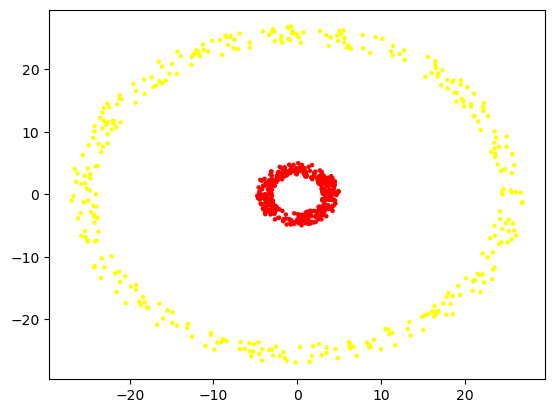

In [21]:
data1 = ring(3, 5)
data2 = ring(24, 27)

data = np.concatenate([data1, data2], axis = 0)
labels = np.concatenate(([0 for i in range(0, len(data1))], [1 for i in range(0, len(data2))]))
plt.scatter(data[:,0], data[:,1], c = labels, s = 5, cmap = "autumn")

# Algoritmo con Kmeans

In [4]:
from sklearn.cluster import KMeans

In [22]:
km = KMeans(2).fit(data)

C:\Users\progr\anaconda3\envs\ml-curso\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


In [23]:
clust = km.predict(data)

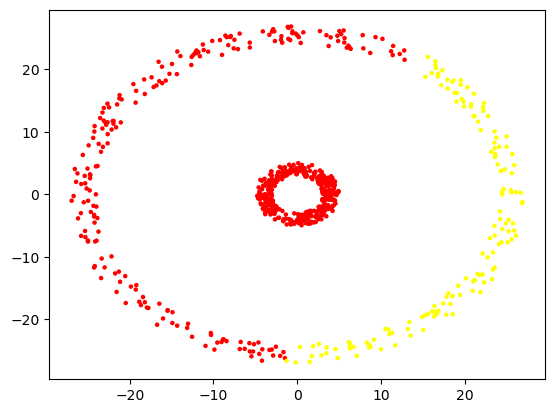

In [24]:
plt.scatter(data[:,0], data[:,1], c = clust, s = 5, cmap="autumn")

# Algoritmo de los K Medoides

In [8]:
from pyclust import KMedoids

In [25]:
kmed = KMedoids(2).fit_predict(data)

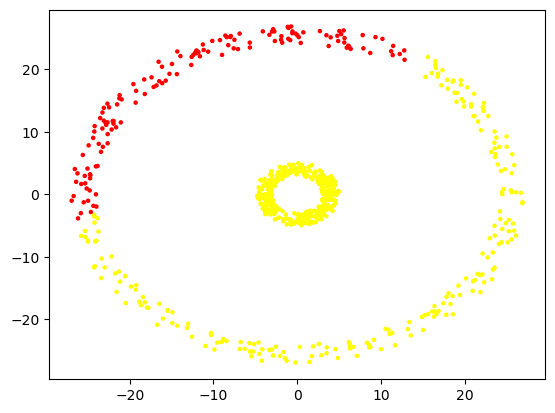

In [26]:
plt.scatter(data[:,0], data[:,1], c = kmed, s = 5, cmap = "autumn")

# Algoritmo del clustering Espectral

In [16]:
from sklearn.cluster import SpectralClustering

In [27]:
clust = SpectralClustering(2).fit_predict(data)

C:\Users\progr\anaconda3\envs\ml-curso\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


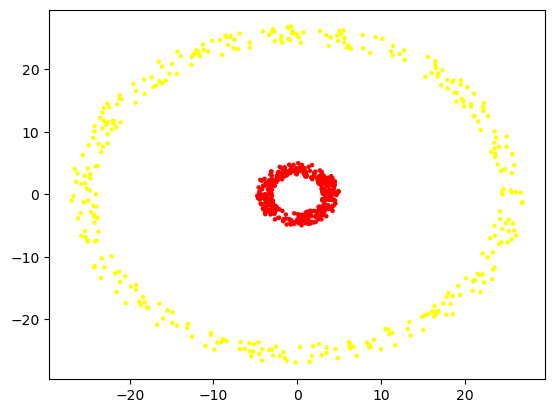

In [28]:
plt.scatter(data[:,0], data[:,1], c = clust, s = 5, cmap = "autumn")

* Podemos estimar la k:
  * NO: Propagacion de la afinidad
  * Si: Podemos usar la distancia Euclidea
    * Si: K-Means
    * No: Buscar valores centrales:
      * Si: K-Medoides
      * No: Los datos son linealmente separables:
        * Si: Clustering aglomerativo
        * No: Clustering Espectral